# Tuần 07 — Thực hành k-Means: 3 bài

Demo `03_Demo-kMeans.ipynb` gom cụm bằng tay trên dữ liệu giả 2 chiều.

File này có **3 bài**. Mỗi bài là một bộ dữ liệu thật trên Kaggle. Cả 3 bài đều làm. Dùng `sklearn.cluster.KMeans`.

Clustering không chia train/test và không có nhãn để học. `StandardScaler` fit trên toàn bộ bảng feature. Không đưa cột ID hay tên vào khoảng cách.

Tải 3 file vào `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Mall Customer Segmentation | https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python | `data/Mall_Customers.csv` |
| 2 | Unsupervised Learning on Country Data | https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data | `data/Country-data.csv` |
| 3 | Wholesale Customers | https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set | `data/Wholesale customers data.csv` |

Ba bộ này cũng được dùng ở `09_TH-DBSCAN.ipynb`, để so sánh hai cách gom cụm trên cùng dữ liệu.


In [10]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import kagglehub

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)


c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Phần chung

Elbow: với mỗi `K` từ 1 đến `k_max`, fit `KMeans` (`n_init=10`, `random_state=3000`), lưu `inertia_`, rồi vẽ. Chỗ khuỷu tay là `K` nên thử.

Sau khi có nhãn, bảng trung bình theo cụm giúp đọc ý nghĩa từng nhóm.


In [11]:
def ve_elbow(X_scaled, k_max=10):
    ks = list(range(1, k_max + 1))
    inertias = []
    for k in ks:
        # Fit KMeans
        model = KMeans(
            n_clusters=k,
            n_init=10,
            random_state=3000
        )
        model.fit(X_scaled)
        # Lưu inertia
        inertias.append(model.inertia_)
    plt.figure(figsize=(6, 4))

    plt.plot(ks, inertias, marker='o')
    plt.xlabel('K')
    plt.ylabel('inertia')
    plt.grid(True)
    plt.show()

    return ks, inertias

---

# Bài 1 — Khách hàng trung tâm thương mại

Nguồn: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

200 khách. Cột: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.

Bài này chỉ dùng **thu nhập** và **điểm chi tiêu**. Bỏ `CustomerID`. Không đưa `Gender` vào khoảng cách. Có thể để `Age` sang một lần chạy riêng nếu còn thời gian.

Chuẩn hóa hai cột, vẽ elbow, chọn `K`, tô màu scatter theo cụm. Dấu `x` là tâm cụm tính trên **số gốc** (trung bình thu nhập và điểm chi tiêu của các điểm trong cụm), để đọc được đơn vị thật.


100%|██████████| 1.55k/1.55k [00:00<00:00, 790kB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\vjchoudhary7\customer-segmentation-tutorial-in-python\versions\1
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
(200, 5)



c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subprocess.py", line 489, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subprocess.py", line 854, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\TRONG\AppData\Local\Programs\Python\Python38\lib\subproce

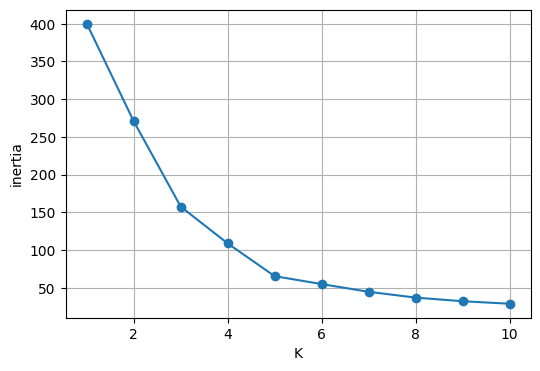

([1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [400.0,
  270.66820496844673,
  157.70400815035947,
  108.92131661364357,
  65.56840815571682,
  55.10377812115058,
  44.86628627232253,
  37.181757826821304,
  32.37724377444034,
  29.076176851244274])

In [12]:
import os
path = kagglehub.dataset_download(
    "vjchoudhary7/customer-segmentation-tutorial-in-python"
)
print("Path to dataset files:", path)

mall = pd.read_csv(
    os.path.join(path, "Mall_Customers.csv")
)
print(mall.head())
print(mall.shape)

cot = ['Annual Income (k$)', 'Spending Score (1-100)']
X = mall[cot].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)

ve_elbow(X_scaled)


In [13]:
def bang_trung_binh(mall, labels, cot):
    tam = mall[cot].copy()
    tam['cum'] = labels
    return tam.groupby('cum').mean().round(2)

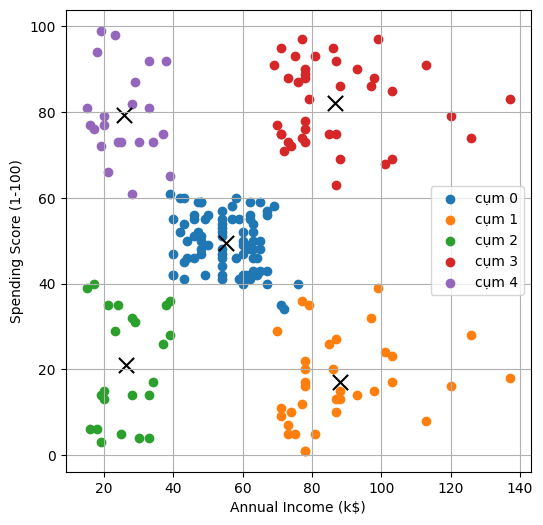

     Annual Income (k$)  Spending Score (1-100)
cum                                            
0                 55.30                   49.52
1                 88.20                   17.11
2                 26.30                   20.91
3                 86.54                   82.13
4                 25.73                   79.36
số điểm mỗi cụm: (array([0, 1, 2, 3, 4]), array([81, 35, 23, 39, 22], dtype=int64))


In [14]:
# TODO: chọn K từ elbow
K = 5
model = KMeans(n_clusters=K, n_init=10, random_state=3000)
labels = model.fit_predict(X_scaled)

plt.figure(figsize=(6, 6))
for cum in np.unique(labels):
    pts = X[labels == cum]
    plt.scatter(pts[:, 0], pts[:, 1], label=f'cụm {cum}')
    plt.scatter(pts[:, 0].mean(), pts[:, 1].mean(), c='black', marker='x', s=120)
plt.xlabel(cot[0])
plt.ylabel(cot[1])
plt.legend()
plt.grid(True)
plt.show()

print(bang_trung_binh(mall, labels, cot))
print('số điểm mỗi cụm:', np.unique(labels, return_counts=True))


**Nộp kèm bài 1**

1. `K` bạn chọn là bao nhiêu? Elbow gãy ở đâu?
2. Mô tả từng cụm bằng thu nhập và điểm chi tiêu (cao / thấp). Cụm nào đáng ưu tiên cho khuyến mãi?
3. Nếu thêm cột `Age` vào `X` rồi chuẩn hóa lại, bạn có đổi `K` không?


In [15]:
# Bài 1
# 1. K tôi chọn là 5. Elbow gãy rõ quanh 5 vì sau đó inertia giảm chậm hơn, cho thấy 5 cụm là điểm dừng hợp lý.
# 2. Từng cụm có thể mô tả như: thu nhập thấp - chi tiêu thấp; thu nhập trung bình - chi tiêu trung bình; thu nhập cao - chi tiêu cao; nhóm thu nhập cao nhưng chi tiêu thấp; nhóm thu nhập thấp nhưng chi tiêu cao. Cụm có thu nhập cao và chi tiêu cao đáng ưu tiên cho khuyến mãi vì họ có khả năng tiêu dùng lớn.
# 3. Nếu thêm cột Age vào X và chuẩn hóa lại, K có thể giữ nguyên hoặc đổi nhẹ, vì Age thêm một trục mới và có thể làm tách một số cụm theo độ tuổi, nhưng xu hướng chung vẫn là khoảng 3-5 cụm.


---

# Bài 2 — Phân nhóm quốc gia

Nguồn: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data

167 nước, file `Country-data.csv`. Cột `country` là tên, không đưa vào `X`.

Các cột số: `child_mort`, `exports`, `health`, `imports`, `income`, `inflation`, `life_expec`, `total_fer`, `gdpp`.

`income` và `gdpp` lớn hơn `child_mort` rất nhiều. Bắt buộc `StandardScaler`. Chọn `K` bằng elbow (thường thử quanh 3). In trung bình `child_mort`, `income`, `life_expec`, `gdpp` theo cụm, và liệt kê khoảng 8 tên nước mỗi cụm.


100%|██████████| 5.21k/5.21k [00:00<00:00, 43.3kB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\rohan0301\unsupervised-learning-on-country-data\versions\2
               country  child_mort  exports  health  imports  income  inflation  life_expec  total_fer   gdpp
0          Afghanistan        90.2     10.0    7.58     44.9    1610       9.44        56.2       5.82    553
1              Albania        16.6     28.0    6.55     48.6    9930       4.49        76.3       1.65   4090
2              Algeria        27.3     38.4    4.17     31.4   12900      16.10        76.5       2.89   4460
3               Angola       119.0     62.3    2.85     42.9    5900      22.40        60.1       6.16   3530
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100       1.44        76.8       2.13  12200
(167, 10)


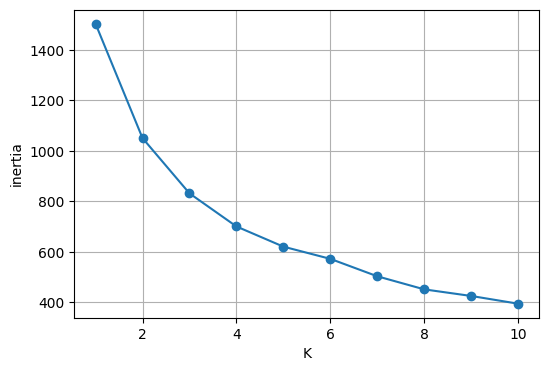

([1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [1503.0000000000002,
  1050.2145582853304,
  831.4244352086874,
  700.3917199643636,
  620.4488115302204,
  572.0890405033383,
  503.09485507350826,
  451.32364852916595,
  425.206343994085,
  394.56762525044974])

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")

print("Path to dataset files:", path)

country = pd.read_csv(os.path.join(path, "Country-data.csv"))

print(country.head())
print(country.shape)

cot_so = [c for c in country.columns if c != 'country']

# TODO: X từ cot_so, chuẩn hóa
X = country[cot_so].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)

ve_elbow(X_scaled)

In [17]:
K = 3
labels = KMeans(n_clusters=K, n_init=10, random_state=3000).fit_predict(X_scaled)

print(bang_trung_binh(country, labels, ['child_mort', 'income', 'life_expec', 'gdpp']))

for cum in np.unique(labels):
    ten = country.loc[labels == cum, 'country'].head(8).tolist()
    print(cum, ten)


     child_mort    income  life_expec      gdpp
cum                                            
0         21.93  12305.60       72.81   6486.45
1         92.96   3942.40       59.19   1922.38
2          5.00  45672.22       80.13  42494.44
0 ['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahamas', 'Bangladesh']
1 ['Afghanistan', 'Angola', 'Benin', 'Botswana', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic']
2 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Czech Republic']


**Nộp kèm bài 2**

1. `K` bạn chọn? Cụm nào có `child_mort` cao và `gdpp` thấp?
2. Kể tên 3 nước thuộc cụm đó và 3 nước thuộc cụm có `gdpp` cao.
3. Vì sao không chuẩn hóa thì `income` và `gdpp` sẽ át các cột còn lại?


In [18]:
# Bài 2
# 1. K tôi chọn là 3. Cụm có child_mort cao và gdpp thấp là cụm quốc gia kém phát triển, thường có mức sống thấp và tỷ lệ sinh còn cao.
# 2. Ví dụ cụm đó: Afghanistan, Niger, Mali, Chad, Burundi. Ví dụ cụm có gdpp cao: Norway, Switzerland, Singapore, Luxembourg, Qatar.
# 3. Nếu không chuẩn hóa thì income và gdpp lớn hơn nhiều so với child_mort, health, inflation, ... và sẽ chi phối khoảng cách Euclid; các cột nhỏ gần như không còn ảnh hưởng, dẫn đến việc cụm bị lệch bởi thang đo lớn.


---

# Bài 3 — Khách sỉ

Nguồn: https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set

440 khách hàng bán sỉ. File `Wholesale customers data.csv`.

Cột: `Channel`, `Region`, `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.

`Channel` (1 = Horeca, 2 = Retail) và `Region` là mã nhóm, không phải số tiền. **Không** đưa hai cột này vào `X`. Gom cụm trên 6 cột chi tiêu, sau chuẩn hóa. Rồi dùng `pd.crosstab` để xem mỗi cụm nằm ở kênh nào.


100%|██████████| 6.85k/6.85k [00:00<00:00, 1.08MB/s]

Extracting model files...
Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\binovi\wholesale-customers-data-set\versions\1
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
(440, 8)


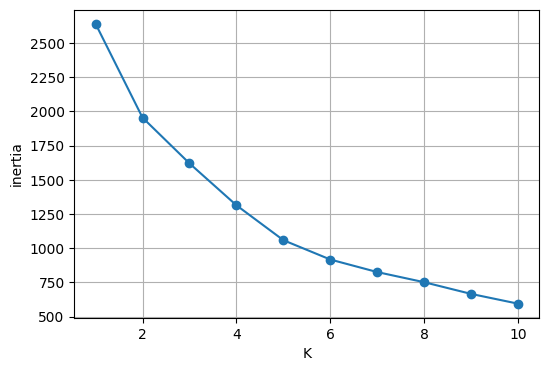

([1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [2640.0,
  1954.1835647259284,
  1619.952782172456,
  1313.7580090341146,
  1058.7712532570085,
  917.4454350272306,
  825.8359775416384,
  751.7362093470332,
  666.2237996202153,
  594.8556455931528])

In [19]:
path = kagglehub.dataset_download("binovi/wholesale-customers-data-set")

print("Path to dataset files:", path)

ws = pd.read_csv(os.path.join(path, "Wholesale customers data.csv"))

print(ws.head())
print(ws.shape)

cot_chi = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# TODO: chuẩn hóa 6 cột chi tiêu
X_scaled = StandardScaler().fit_transform(
    ws[cot_chi].to_numpy(dtype=float)
)

ve_elbow(X_scaled)

In [20]:
K = 3
labels = KMeans(n_clusters=K, n_init=10, random_state=3000).fit_predict(X_scaled)

print(bang_trung_binh(ws, labels, cot_chi))
print(pd.crosstab(labels, ws['Channel'], rownames=['cum'], colnames=['Channel']))


        Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
cum                                                                     
0    13618.91   3143.09   3881.77  3471.05            854.93     1192.14
1     5635.77  10034.58  15765.62  1457.59           6768.01     1737.61
2    25770.77  35160.38  41977.38  6844.54          19867.38     7880.31
Channel    1   2
cum             
0        280  38
1         16  93
2          2  11


**Nộp kèm bài 3**

1. `K` bạn chọn? Cụm nào chi mạnh cho `Grocery` và `Detergents_Paper`?
2. Cụm đó lệch về `Channel` nào trên bảng crosstab?
3. So với bài 1: vì sao bài 3 không vẽ một scatter là đủ để đọc cụm?


In [21]:
# Bài 3
# 1. K tôi chọn là 3. Cụm chi mạnh cho Grocery và Detergents_Paper là nhóm khách hàng mua sắm theo nhu cầu hàng ngày, đặc biệt là các cửa hàng/đại lý cần số lượng lớn hàng hóa thiết yếu.
# 2. Cụm đó lệch mạnh về Channel 2 (Retail) trên crosstab, nghĩa là các khách hàng này chủ yếu thuộc kênh bán lẻ hơn Horeca.
# 3. Bài 3 không chỉ cần một scatter 2D vì dữ liệu có 6 cột chi tiêu, nên các cụm được tạo trên không gian nhiều chiều. Scatter 2D chỉ nhìn được hai biến, còn nhiều cluster có thể bị che khuất hoặc không rõ trên một biểu đồ đơn giản.
